In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("../data/heart_disease_data.csv")
print("Dataset Shape", df.shape)
df.head()

Dataset Shape (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Fix labels and missing codes
In this dataset `target` is **inverted**: `1` = healthy, `0` = disease (target=1 patients are younger, have higher max heart rate, less exercise angina and fewer blocked vessels).
We create `disease = 1 - target` and mark `ca=4` / `thal=0` as missing.

In [3]:
df['ca'] = df['ca'].replace(4, np.nan)
df['thal'] = df['thal'].replace(0, np.nan)
df['disease'] = 1 - df['target']
df = df.drop(columns='target').rename(columns={'disease': 'target'})
df = df.fillna(df.median(numeric_only=True))
df.groupby('target')[['age', 'thalach', 'oldpeak', 'exang', 'ca']].mean()

,age,thalach,oldpeak,exang,ca
target,,,,,
0,52.496970,158.466667,0.583030,0.139394,0.266667
1,56.601449,139.101449,1.585507,0.550725,1.137681


In [4]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    float64
 12  thal      303 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [5]:
print("Missing values:", df.isnull().sum().sum())
print(df['target'].value_counts())
print(f"balance: {df['target'].value_counts()[1] / df['target'].value_counts()[0]:.2f}:1")

Missing values: 0
target
0    165
1    138
Name: count, dtype: int64
balance: 0.84:1


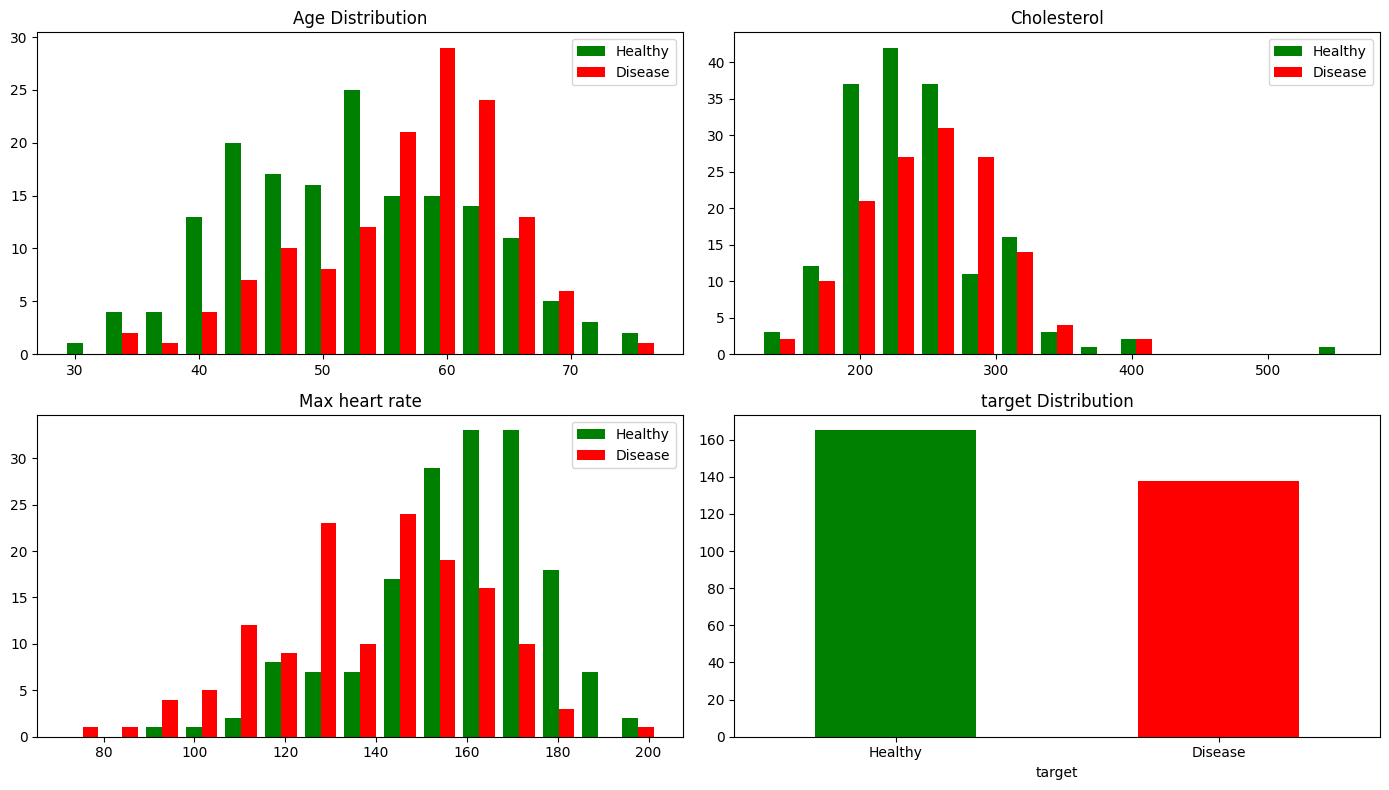

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14,8))

axes[0,0].hist([df[df['target']==0]['age'], df[df['target']==1]['age']],
                label=['Healthy','Disease'], bins=15, color=['green','red'])
axes[0, 0].set_title('Age Distribution')
axes[0,0].legend()

axes[0,1].hist([df[df['target']==0]['chol'], df[df['target']==1]['chol']],
                label=['Healthy','Disease'], bins=15, color=['green','red'])
axes[0,1].set_title('Cholesterol')
axes[0,1].legend()

axes[1,0].hist([df[df['target']==0]['thalach'], df[df['target']==1]['thalach']],
                label=['Healthy','Disease'], bins=15, color=['green','red'])
axes[1,0].set_title('Max heart rate')
axes[1,0].legend()

df['target'].value_counts().plot(kind='bar', ax=axes[1,1], color=['green','red'])
axes[1,1].set_title('target Distribution')
axes[1,1].set_xticklabels(['Healthy','Disease'], rotation=0)

plt.tight_layout()
plt.show()

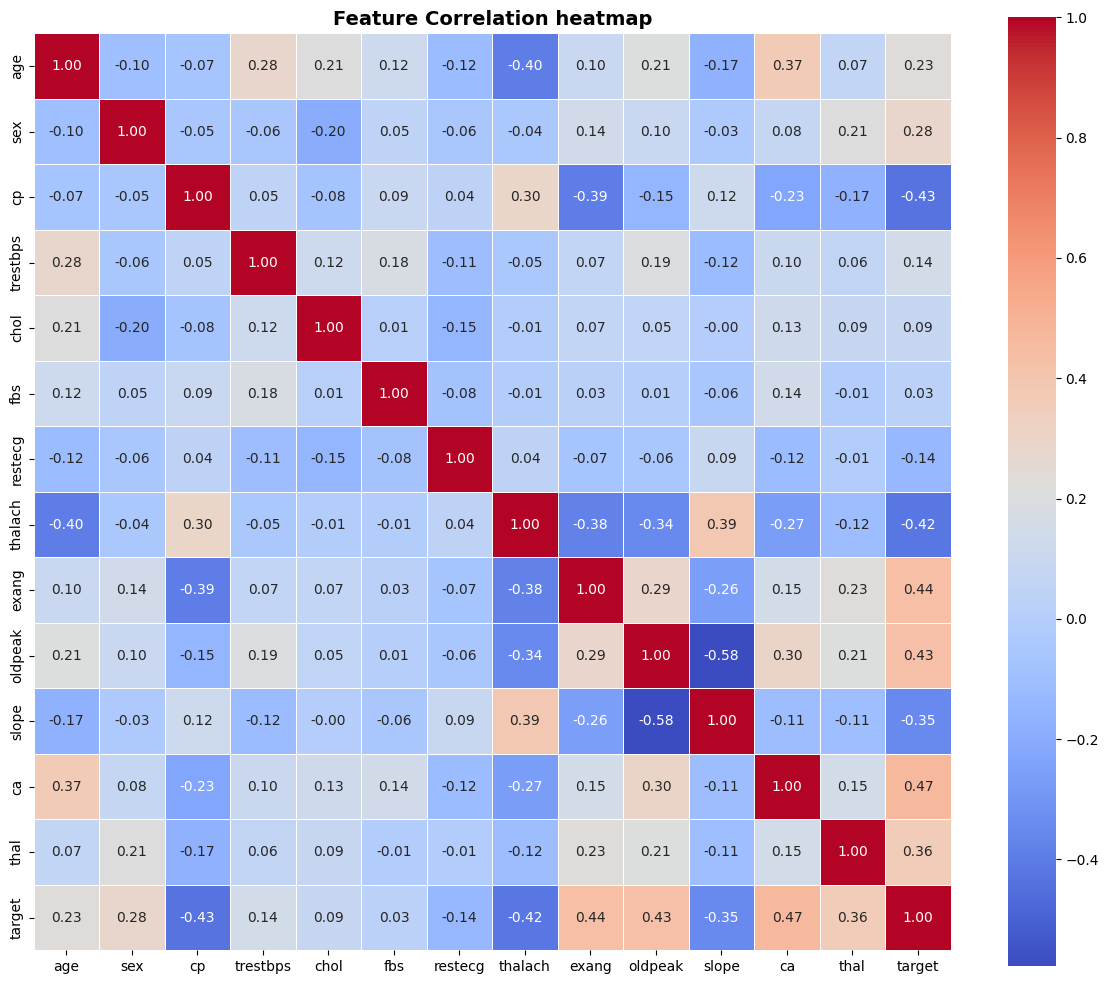

In [7]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, square=True)
plt.title('Feature Correlation heatmap',fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
x=df.drop(columns='target', axis=1)
y=df['target']

print(x.shape)
print(y.shape)

(303, 13)
(303,)


In [9]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(x_train.shape[0])
print(x_test.shape[0])

242
61


In [10]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)



In [11]:
model= LogisticRegression(max_iter=1000, random_state=42)
score = cross_val_score(model, x_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"{score.mean():4f} (+/-{score.std():.4f})")

0.855017 (+/-0.0544)


In [12]:
model.fit(x_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [13]:
y_train_pred = model.predict(x_train_scaled)
y_test_pred = model.predict(x_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(train_acc)
print(test_acc)
print(classification_report(y_test, y_test_pred, target_names=['Healthy', 'Disease']))

0.8801652892561983
0.8688524590163934
              precision    recall  f1-score   support

     Healthy       0.86      0.91      0.88        33
     Disease       0.88      0.82      0.85        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



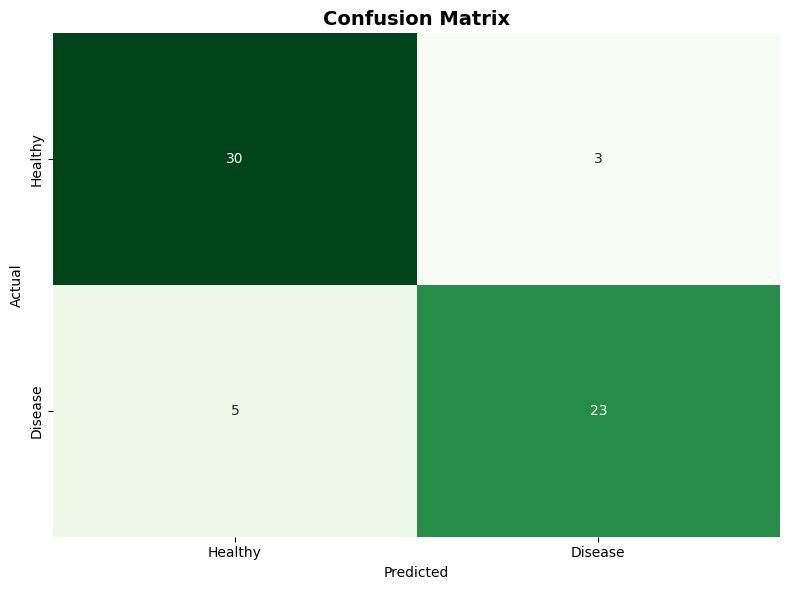

In [14]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, 
            xticklabels=['Healthy', 'Disease'], yticklabels=['Healthy', 'Disease'])
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

## Save the deployed model
`train.py` builds the full pipeline (imputation, scaling, one-hot encoding + model) used by `app.py`.

In [15]:
import sys
sys.path.append('..')
import train
train.main()

Logistic Regression  CV ROC-AUC 0.907 (+/- 0.030)


Random Forest        CV ROC-AUC 0.915 (+/- 0.027)
Selected: Logistic Regression
              precision    recall  f1-score   support

     Healthy       0.85      0.88      0.87        33
     Disease       0.85      0.82      0.84        28

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61

{
  "model_name": "Logistic Regression",
  "features": [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal"
  ],
  "test_accuracy": 0.852,
  "test_roc_auc": 0.927,
  "cv_roc_auc": 0.907,
  "n_samples": 303,
  "label_note": "Trained on disease = 1 - target (target is inverted in source CSV)"
}
Sanity fit: disease risk = 3.7%
Sanity sick: disease risk = 99.9%
